# Temporary Laptop Sound Classifier

This notebook is a temporary demo runtime for the panel presentation. It skips context awareness and personalization, and instead uses the exported SoundPulse YAMNet embedding backbone together with the exported prototype store to classify short sound clips captured from the laptop microphone or any connected microphone.

The flow is: load exported artifacts, reproduce runtime audio preprocessing, capture 1 second clips, extract embeddings with YAMNet, and score each clip against the class prototypes.

In [ ]:
#%pip install -q -e .. sounddevice

## Load Project Paths and Exported Artifacts

This cell resolves the repository root, loads the shared contracts, and reads the exported YAMNet metadata and prototype store. It also exposes one place to set the microphone device for the demo if the default input is not the one you want.

In [1]:
from __future__ import annotations

import json
import math
import sys
import time
from datetime import datetime
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sounddevice as sd
import soundfile as sf
import tensorflow as tf
from IPython.display import Audio, display


def resolve_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / 'ml').exists() and (candidate / 'packages' / 'shared_contracts' / 'v1').exists():
            return candidate
    raise FileNotFoundError('Could not resolve the SoundPulse project root from the current notebook location.')


NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = resolve_project_root(NOTEBOOK_DIR)
ML_ROOT = PROJECT_ROOT / 'ml'
SRC_ROOT = ML_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

CONTRACTS_DIR = PROJECT_ROOT / 'packages' / 'shared_contracts' / 'v1'
MODEL_DIR = ML_ROOT / 'export' / 'artifacts' / 'generated' / 'yamnet_kaggle'
PROTOTYPE_PATH = MODEL_DIR / 'prototype_store.json'
ARTIFACT_SUMMARY_PATH = MODEL_DIR / 'artifact_summary.json'

with (CONTRACTS_DIR / 'class_labels.json').open('r', encoding='utf-8') as handle:
    CLASS_CONTRACT = json.load(handle)
with (CONTRACTS_DIR / 'preprocessing_config.json').open('r', encoding='utf-8') as handle:
    PREPROCESSING_CONTRACT = json.load(handle)
with (CONTRACTS_DIR / 'threshold_defaults.json').open('r', encoding='utf-8') as handle:
    THRESHOLD_DEFAULTS = json.load(handle)
with ARTIFACT_SUMMARY_PATH.open('r', encoding='utf-8') as handle:
    ARTIFACT_SUMMARY = json.load(handle)
with PROTOTYPE_PATH.open('r', encoding='utf-8') as handle:
    PROTOTYPE_STORE = {key: np.asarray(value, dtype=np.float32) for key, value in json.load(handle).items()}

CLASS_ORDER = ARTIFACT_SUMMARY['class_order']
DISPLAY_NAME_BY_SLUG = {item['slug']: item['display_name'] for item in CLASS_CONTRACT['classes']}
URGENT_BY_SLUG = {item['slug']: item['urgent'] for item in CLASS_CONTRACT['classes']}
SAMPLE_RATE = int(PREPROCESSING_CONTRACT['audio']['sample_rate_hz'])
WINDOW_DURATION_MS = int(PREPROCESSING_CONTRACT['audio']['window_duration_ms'])
WINDOW_SAMPLES = int(SAMPLE_RATE * WINDOW_DURATION_MS / 1000)
CHANNELS = int(PREPROCESSING_CONTRACT['audio']['channels'])
DISTANCE_THRESHOLD = float(THRESHOLD_DEFAULTS['distance_threshold'])
LOUDNESS_FLOOR_DBFS = float(THRESHOLD_DEFAULTS['loudness_floor_dbfs'])
CONFIDENCE_TIERS = THRESHOLD_DEFAULTS['confidence_tiers']
INPUT_DEVICE = None

print({
    'project_root': str(PROJECT_ROOT),
    'yamnet_artifact': ARTIFACT_SUMMARY['yamnet_artifact'],
    'prototype_classes': sorted(PROTOTYPE_STORE.keys()),
    'sample_rate_hz': SAMPLE_RATE,
    'window_samples': WINDOW_SAMPLES,
    'distance_threshold': DISTANCE_THRESHOLD,
    'loudness_floor_dbfs': LOUDNESS_FLOOR_DBFS,
    'embedding_dim': ARTIFACT_SUMMARY.get('embedding_dim'),
    'default_input_device': sd.default.device[0],
})

{'project_root': 'C:\\Users\\ZBOOK STUDIO G5\\Documents\\GitHub\\SoundPulse', 'yamnet_artifact': 'C:\\Users\\ZBOOK STUDIO G5\\.cache\\kagglehub\\models\\google\\yamnet\\tensorFlow2\\yamnet\\1\\saved_model.pb', 'prototype_classes': ['background', 'clock_alarm', 'crying_baby', 'dog_barking', 'door_knock', 'door_wood_creaking', 'doorbell', 'fire_alarm', 'speech', 'water_running'], 'sample_rate_hz': 16000, 'window_samples': 15712, 'distance_threshold': 0.85, 'loudness_floor_dbfs': -52.0, 'embedding_dim': 1024, 'default_input_device': 1}


## Define Preprocessing and YAMNet Inference Helpers

These helpers keep the runtime aligned with the model export. The code converts any waveform to mono float32 audio, resamples to 16 kHz, pads or trims to exactly one second, runs the YAMNet embedding model, and scores the embedding against the exported prototypes.

In [2]:
yamnet_artifact = Path(ARTIFACT_SUMMARY['yamnet_artifact'])


def load_yamnet_model(artifact_path: Path):
    if artifact_path.name == 'saved_model.pb':
        return tf.saved_model.load(str(artifact_path.parent))
    return tf.keras.models.load_model(str(artifact_path))


yamnet_model = load_yamnet_model(yamnet_artifact)


def to_mono_float32(waveform: np.ndarray) -> np.ndarray:
    array = np.asarray(waveform, dtype=np.float32)
    if array.ndim == 2:
        array = array.mean(axis=1)
    return array.astype(np.float32, copy=False)


def resample_audio(waveform: np.ndarray, source_sample_rate: int, target_sample_rate: int) -> np.ndarray:
    if int(source_sample_rate) == int(target_sample_rate):
        return waveform.astype(np.float32, copy=False)
    return librosa.resample(waveform, orig_sr=int(source_sample_rate), target_sr=int(target_sample_rate)).astype(np.float32)


def fit_to_window(waveform: np.ndarray, window_samples: int = WINDOW_SAMPLES) -> np.ndarray:
    if waveform.shape[0] < window_samples:
        padding = window_samples - waveform.shape[0]
        waveform = np.pad(waveform, (0, padding))
    return waveform[:window_samples].astype(np.float32, copy=False)


def compute_loudness_dbfs(waveform: np.ndarray) -> float:
    rms = float(np.sqrt(np.mean(np.square(waveform), dtype=np.float64)))
    return 20.0 * math.log10(max(rms, 1e-8))


def resolve_embedding_tensor(output: object) -> np.ndarray:
    if isinstance(output, dict):
        for value in output.values():
            value_np = np.array(value)
            if value_np.ndim >= 2 and value_np.shape[-1] == 1024:
                return value_np
    if isinstance(output, (list, tuple)):
        for value in output:
            value_np = np.array(value)
            if value_np.ndim >= 2 and value_np.shape[-1] == 1024:
                return value_np
    value_np = np.array(output)
    if value_np.ndim >= 2 and value_np.shape[-1] == 1024:
        return value_np
    raise ValueError('Unable to resolve a 1024-d embedding tensor from YAMNet output')


def extract_embedding(waveform: np.ndarray) -> np.ndarray:
    input_tensor = tf.convert_to_tensor(waveform, dtype=tf.float32)
    if hasattr(yamnet_model, 'signatures') and yamnet_model.signatures:
        signature = next(iter(yamnet_model.signatures.values()))
        output = signature(input_tensor)
    else:
        output = yamnet_model(input_tensor)
    embedding_frames = resolve_embedding_tensor(output)
    if embedding_frames.ndim == 1:
        embedding_frames = np.expand_dims(embedding_frames, axis=0)
    return embedding_frames.mean(axis=0).astype(np.float32)


def score_embedding(embedding: np.ndarray) -> list[tuple[str, float]]:
    scores = []
    for class_slug, prototype in PROTOTYPE_STORE.items():
        distance = float(np.sum((embedding - prototype) ** 2))
        scores.append((class_slug, distance))
    scores.sort(key=lambda item: item[1])
    return scores


def confidence_tier(distance: float) -> tuple[float, str]:
    confidence_score = float(np.clip(1.0 - (distance / max(DISTANCE_THRESHOLD, 1e-6)), 0.0, 1.0))
    if confidence_score >= float(CONFIDENCE_TIERS['high']):
        tier = 'high'
    elif confidence_score >= float(CONFIDENCE_TIERS['medium']):
        tier = 'medium'
    elif confidence_score >= float(CONFIDENCE_TIERS['low']):
        tier = 'low'
    else:
        tier = 'very_low'
    return confidence_score, tier


def classify_waveform(waveform: np.ndarray, source_sample_rate: int) -> dict:
    mono_waveform = to_mono_float32(waveform)
    mono_waveform = resample_audio(mono_waveform, source_sample_rate, SAMPLE_RATE)
    mono_waveform = fit_to_window(mono_waveform)
    loudness_dbfs = compute_loudness_dbfs(mono_waveform)
    embedding = extract_embedding(mono_waveform)
    ranked_scores = score_embedding(embedding)
    nearest_slug, nearest_distance = ranked_scores[0]

    if loudness_dbfs < LOUDNESS_FLOOR_DBFS:
        predicted_slug = 'background'
        decision_reason = 'below_loudness_floor'
    elif nearest_distance > DISTANCE_THRESHOLD:
        predicted_slug = 'background'
        decision_reason = 'distance_threshold_exceeded'
    else:
        predicted_slug = nearest_slug
        decision_reason = 'nearest_prototype'

    confidence_score, tier = confidence_tier(nearest_distance)
    top_matches = [
        {
            'slug': slug,
            'display_name': DISPLAY_NAME_BY_SLUG.get(slug, slug.replace('_', ' ')),
            'distance': round(distance, 4),
        }
        for slug, distance in ranked_scores[:3]
    ]

    return {
        'predicted_slug': predicted_slug,
        'predicted_label': DISPLAY_NAME_BY_SLUG.get(predicted_slug, predicted_slug.replace('_', ' ')),
        'nearest_slug': nearest_slug,
        'nearest_label': DISPLAY_NAME_BY_SLUG.get(nearest_slug, nearest_slug.replace('_', ' ')),
        'distance': round(nearest_distance, 4),
        'loudness_dbfs': round(loudness_dbfs, 2),
        'confidence_score': round(confidence_score, 3),
        'confidence_tier': tier,
        'urgent': bool(URGENT_BY_SLUG.get(predicted_slug, False)),
        'decision_reason': decision_reason,
        'top_matches': top_matches,
        'waveform': mono_waveform,
        'embedding': embedding,
    }


print({
    'yamnet_artifact': str(yamnet_artifact),
    'prototype_count': len(PROTOTYPE_STORE),
    'embedding_dim': ARTIFACT_SUMMARY.get('embedding_dim'),
})

{'yamnet_artifact': 'C:\\Users\\ZBOOK STUDIO G5\\.cache\\kagglehub\\models\\google\\yamnet\\tensorFlow2\\yamnet\\1\\saved_model.pb', 'prototype_count': 10, 'embedding_dim': 1024}


## Add Microphone and Fallback File Helpers

The next cell adds practical demo utilities. You can inspect available input devices, capture a single microphone clip, run a short live loop, or classify an existing audio file if you want a fallback path before the panel starts.

In [3]:
def list_input_devices() -> pd.DataFrame:
    default_input_device = sd.default.device[0]
    hostapis = sd.query_hostapis()
    records = []
    for index, device in enumerate(sd.query_devices()):
        if int(device['max_input_channels']) > 0:
            hostapi_index = int(device['hostapi'])
            records.append({
                'device_index': index,
                'name': device['name'],
                'hostapi_index': hostapi_index,
                'hostapi_name': hostapis[hostapi_index]['name'],
                'max_input_channels': int(device['max_input_channels']),
                'default_samplerate': int(device['default_samplerate']),
                'is_default_input': index == default_input_device,
            })
    return pd.DataFrame(records)


def resolve_input_device(device: int | str | None = None) -> int | None:
    if device is None:
        return sd.default.device[0]
    if isinstance(device, int):
        return device
    matches = [
        index
        for index, candidate in enumerate(sd.query_devices())
        if int(candidate['max_input_channels']) > 0 and candidate['name'] == device
    ]
    if not matches:
        raise ValueError(f'No input device matched {device!r}. Check the device_index values in available_inputs.')
    if len(matches) == 1:
        return matches[0]
    default_input_device = sd.default.device[0]
    if default_input_device in matches:
        return default_input_device
    raise ValueError(
        f"{device!r} matches multiple input devices: {matches}. Use the device_index from available_inputs instead."
    )


def get_input_device_info(device: int | str | None = None) -> dict:
    resolved_device = resolve_input_device(device)
    return sd.query_devices(device=resolved_device, kind='input') if resolved_device is not None else sd.query_devices(kind='input')


def capture_audio(seconds: float = 1.0, device: int | str | None = None) -> tuple[np.ndarray, int, dict]:
    device_info = get_input_device_info(device)
    capture_sample_rate = int(device_info['default_samplerate'])
    frame_count = max(1, int(seconds * capture_sample_rate))
    recording = sd.rec(
        frame_count,
        samplerate=capture_sample_rate,
        channels=CHANNELS,
        dtype='float32',
        device=resolve_input_device(device),
    )
    sd.wait()
    return np.squeeze(recording), capture_sample_rate, device_info


def plot_waveform(waveform: np.ndarray, sample_rate: int = SAMPLE_RATE, title: str = 'Captured waveform') -> None:
    times = np.arange(waveform.shape[0]) / sample_rate
    plt.figure(figsize=(12, 3))
    plt.plot(times, waveform, linewidth=1.0)
    plt.title(title)
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


def summarize_result(result: dict) -> dict:
    return {
        'predicted_label': result['predicted_label'],
        'nearest_label': result['nearest_label'],
        'distance': result['distance'],
        'loudness_dbfs': result['loudness_dbfs'],
        'confidence_score': result['confidence_score'],
        'confidence_tier': result['confidence_tier'],
        'urgent': result['urgent'],
        'decision_reason': result['decision_reason'],
        'top_matches': result['top_matches'],
    }


def classify_microphone_clip(seconds: float = 1.0, device: int | str | None = None, plot: bool = True, play_audio: bool = False) -> dict:
    waveform, source_sample_rate, device_info = capture_audio(seconds=seconds, device=device)
    result = classify_waveform(waveform, source_sample_rate)
    result['captured_at'] = datetime.now().strftime('%H:%M:%S')
    result['device_name'] = device_info['name']
    result['source_sample_rate'] = source_sample_rate
    if play_audio:
        display(Audio(result['waveform'], rate=SAMPLE_RATE))
    if plot:
        plot_waveform(result['waveform'], sample_rate=SAMPLE_RATE, title=f"Prediction: {result['predicted_label']}")
    return summarize_result(result)


def classify_audio_file(audio_path: str | Path, plot: bool = True, play_audio: bool = False) -> dict:
    waveform, source_sample_rate = sf.read(str(audio_path), dtype='float32', always_2d=False)
    result = classify_waveform(waveform, source_sample_rate)
    result['audio_path'] = str(audio_path)
    if play_audio:
        display(Audio(result['waveform'], rate=SAMPLE_RATE))
    if plot:
        plot_waveform(result['waveform'], sample_rate=SAMPLE_RATE, title=f"File prediction: {result['predicted_label']}")
    return summarize_result(result)


def run_live_demo(iterations: int = 10, seconds: float = 1.0, device: int | str | None = None, pause_seconds: float = 0.15) -> pd.DataFrame:
    rows = []
    try:
        for iteration in range(iterations):
            result = classify_microphone_clip(seconds=seconds, device=device, plot=False, play_audio=False)
            row = {
                'segment': iteration + 1,
                'captured_at': datetime.now().strftime('%H:%M:%S'),
                **result,
            }
            rows.append(row)
            print(
                f"[{row['captured_at']}] segment={row['segment']:02d} predicted={row['predicted_label']} nearest={row['nearest_label']} distance={row['distance']:.4f} loudness_dbfs={row['loudness_dbfs']:.2f}"
            )
            time.sleep(max(0.0, pause_seconds))
    except KeyboardInterrupt:
        print('Live demo interrupted by user.')
    return pd.DataFrame(rows)

## Inspect Microphone Inputs

Run this once before the live demo. If you want to force a specific microphone, copy its `device_index` into the `INPUT_DEVICE` variable in the earlier setup cell, then rerun the helper cells.

In [4]:
available_inputs = list_input_devices()
available_inputs

,device_index,name,hostapi_index,hostapi_name,max_input_channels,default_samplerate,is_default_input
0,0,Microsoft Sound Mapper - Input,0,MME,2,44100,False
1,1,Microphone (Conexant ISST Audio,0,MME,4,44100,True
2,2,Microphone (USB2.0 Device),0,MME,1,44100,False
3,5,Primary Sound Capture Driver,1,Windows DirectSound,2,44100,False
4,6,Microphone (Conexant ISST Audio),1,Windows DirectSound,4,44100,False
5,7,Microphone (USB2.0 Device),1,Windows DirectSound,1,44100,False
6,11,Microphone (USB2.0 Device),2,Windows WASAPI,1,48000,False
7,12,Microphone (Conexant ISST Audio),2,Windows WASAPI,4,48000,False
8,14,"Headset (@System32\drivers\bthhfenum.sys,#2;%1...",3,Windows WDM-KS,1,8000,False
9,16,"Headset (@System32\drivers\bthhfenum.sys,#2;%1...",3,Windows WDM-KS,1,8000,False


## Run a One-Shot Microphone Classification

This is the fastest smoke test before the presentation. It records one 1 second clip, classifies it, and plots the normalized waveform so you can confirm the notebook is capturing audio from the expected device.

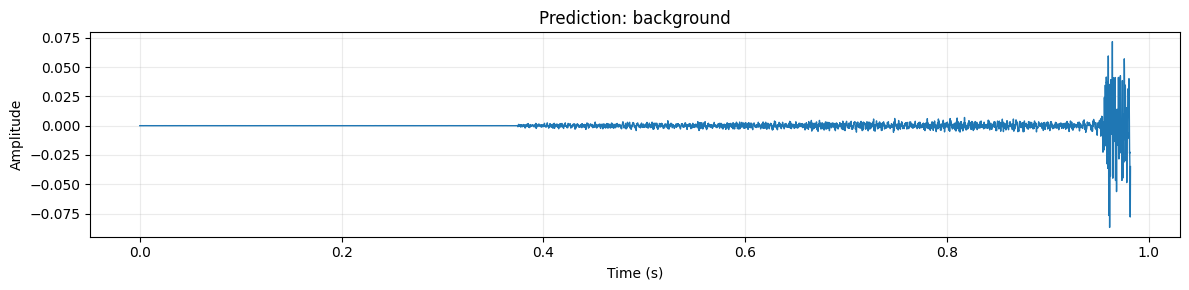

{'predicted_label': 'background',
 'nearest_label': 'speech',
 'distance': 23.2285,
 'loudness_dbfs': -46.09,
 'confidence_score': 0.0,
 'confidence_tier': 'very_low',
 'urgent': False,
 'decision_reason': 'distance_threshold_exceeded',
 'top_matches': [{'slug': 'speech',
   'display_name': 'speech',
   'distance': 23.2285},
  {'slug': 'door_wood_creaking',
   'display_name': 'door wood creaking',
   'distance': 24.9387},
  {'slug': 'fire_alarm', 'display_name': 'fire alarm', 'distance': 34.9653}]}

In [5]:
one_shot_result = classify_microphone_clip(seconds=1.0, device=INPUT_DEVICE, plot=True, play_audio=True)
one_shot_result

## Run a Short Live Demo Loop

This cell records and classifies several 1 second windows back to back. Keep the iteration count modest for the panel demo so the notebook stays responsive, and interrupt the kernel only if you deliberately increase the count and want to stop early.

In [ ]:
live_demo_results = run_live_demo(iterations=10, seconds=1.0, device=INPUT_DEVICE, pause_seconds=0.1)
live_demo_results

[16:06:45] segment=01 predicted=background nearest=speech distance=16.2965 loudness_dbfs=-44.91
[16:06:49] segment=02 predicted=background nearest=door wood creaking distance=26.8994 loudness_dbfs=-45.34
[16:06:54] segment=03 predicted=background nearest=speech distance=21.8867 loudness_dbfs=-43.37
[16:06:58] segment=04 predicted=background nearest=speech distance=19.0598 loudness_dbfs=-47.75
[16:07:03] segment=05 predicted=background nearest=speech distance=18.6084 loudness_dbfs=-43.71
[16:07:07] segment=06 predicted=background nearest=speech distance=17.9599 loudness_dbfs=-45.81
[16:07:11] segment=07 predicted=background nearest=speech distance=9.4830 loudness_dbfs=-32.75
[16:07:16] segment=08 predicted=background nearest=speech distance=18.9831 loudness_dbfs=-33.71
[16:07:20] segment=09 predicted=background nearest=speech distance=48.3873 loudness_dbfs=-37.42
[16:07:25] segment=10 predicted=background nearest=speech distance=20.1658 loudness_dbfs=-44.03


,segment,captured_at,predicted_label,nearest_label,distance,loudness_dbfs,confidence_score,confidence_tier,urgent,decision_reason,top_matches
0,1,16:06:45,background,speech,16.2965,-44.91,0.0,very_low,False,distance_threshold_exceeded,"[{'slug': 'speech', 'display_name': 'speech', ..."
1,2,16:06:49,background,door wood creaking,26.8994,-45.34,0.0,very_low,False,distance_threshold_exceeded,"[{'slug': 'door_wood_creaking', 'display_name'..."
2,3,16:06:54,background,speech,21.8867,-43.37,0.0,very_low,False,distance_threshold_exceeded,"[{'slug': 'speech', 'display_name': 'speech', ..."
3,4,16:06:58,background,speech,19.0598,-47.75,0.0,very_low,False,distance_threshold_exceeded,"[{'slug': 'speech', 'display_name': 'speech', ..."
4,5,16:07:03,background,speech,18.6084,-43.71,0.0,very_low,False,distance_threshold_exceeded,"[{'slug': 'speech', 'display_name': 'speech', ..."
5,6,16:07:07,background,speech,17.9599,-45.81,0.0,very_low,False,distance_threshold_exceeded,"[{'slug': 'speech', 'display_name': 'speech', ..."
6,7,16:07:11,background,speech,9.4830,-32.75,0.0,very_low,False,distance_threshold_exceeded,"[{'slug': 'speech', 'display_name': 'speech', ..."
7,8,16:07:16,background,speech,18.9831,-33.71,0.0,very_low,False,distance_threshold_exceeded,"[{'slug': 'speech', 'display_name': 'speech', ..."
8,9,16:07:20,background,speech,48.3873,-37.42,0.0,very_low,False,distance_threshold_exceeded,"[{'slug': 'speech', 'display_name': 'speech', ..."
9,10,16:07:25,background,speech,20.1658,-44.03,0.0,very_low,False,distance_threshold_exceeded,"[{'slug': 'speech', 'display_name': 'speech', ..."


## Optional Fallback: Classify a Local Audio File

If you want to dry-run the demo without speaking into the microphone, or if the room setup causes issues, set a local WAV path below and classify that file with the same preprocessing and prototype scoring pipeline.

In [ ]:
DEMO_AUDIO_PATH = None

if DEMO_AUDIO_PATH is None:
    print('Set DEMO_AUDIO_PATH to a local WAV file path to use the file-based fallback.')
else:
    classify_audio_file(DEMO_AUDIO_PATH, plot=True, play_audio=False)